
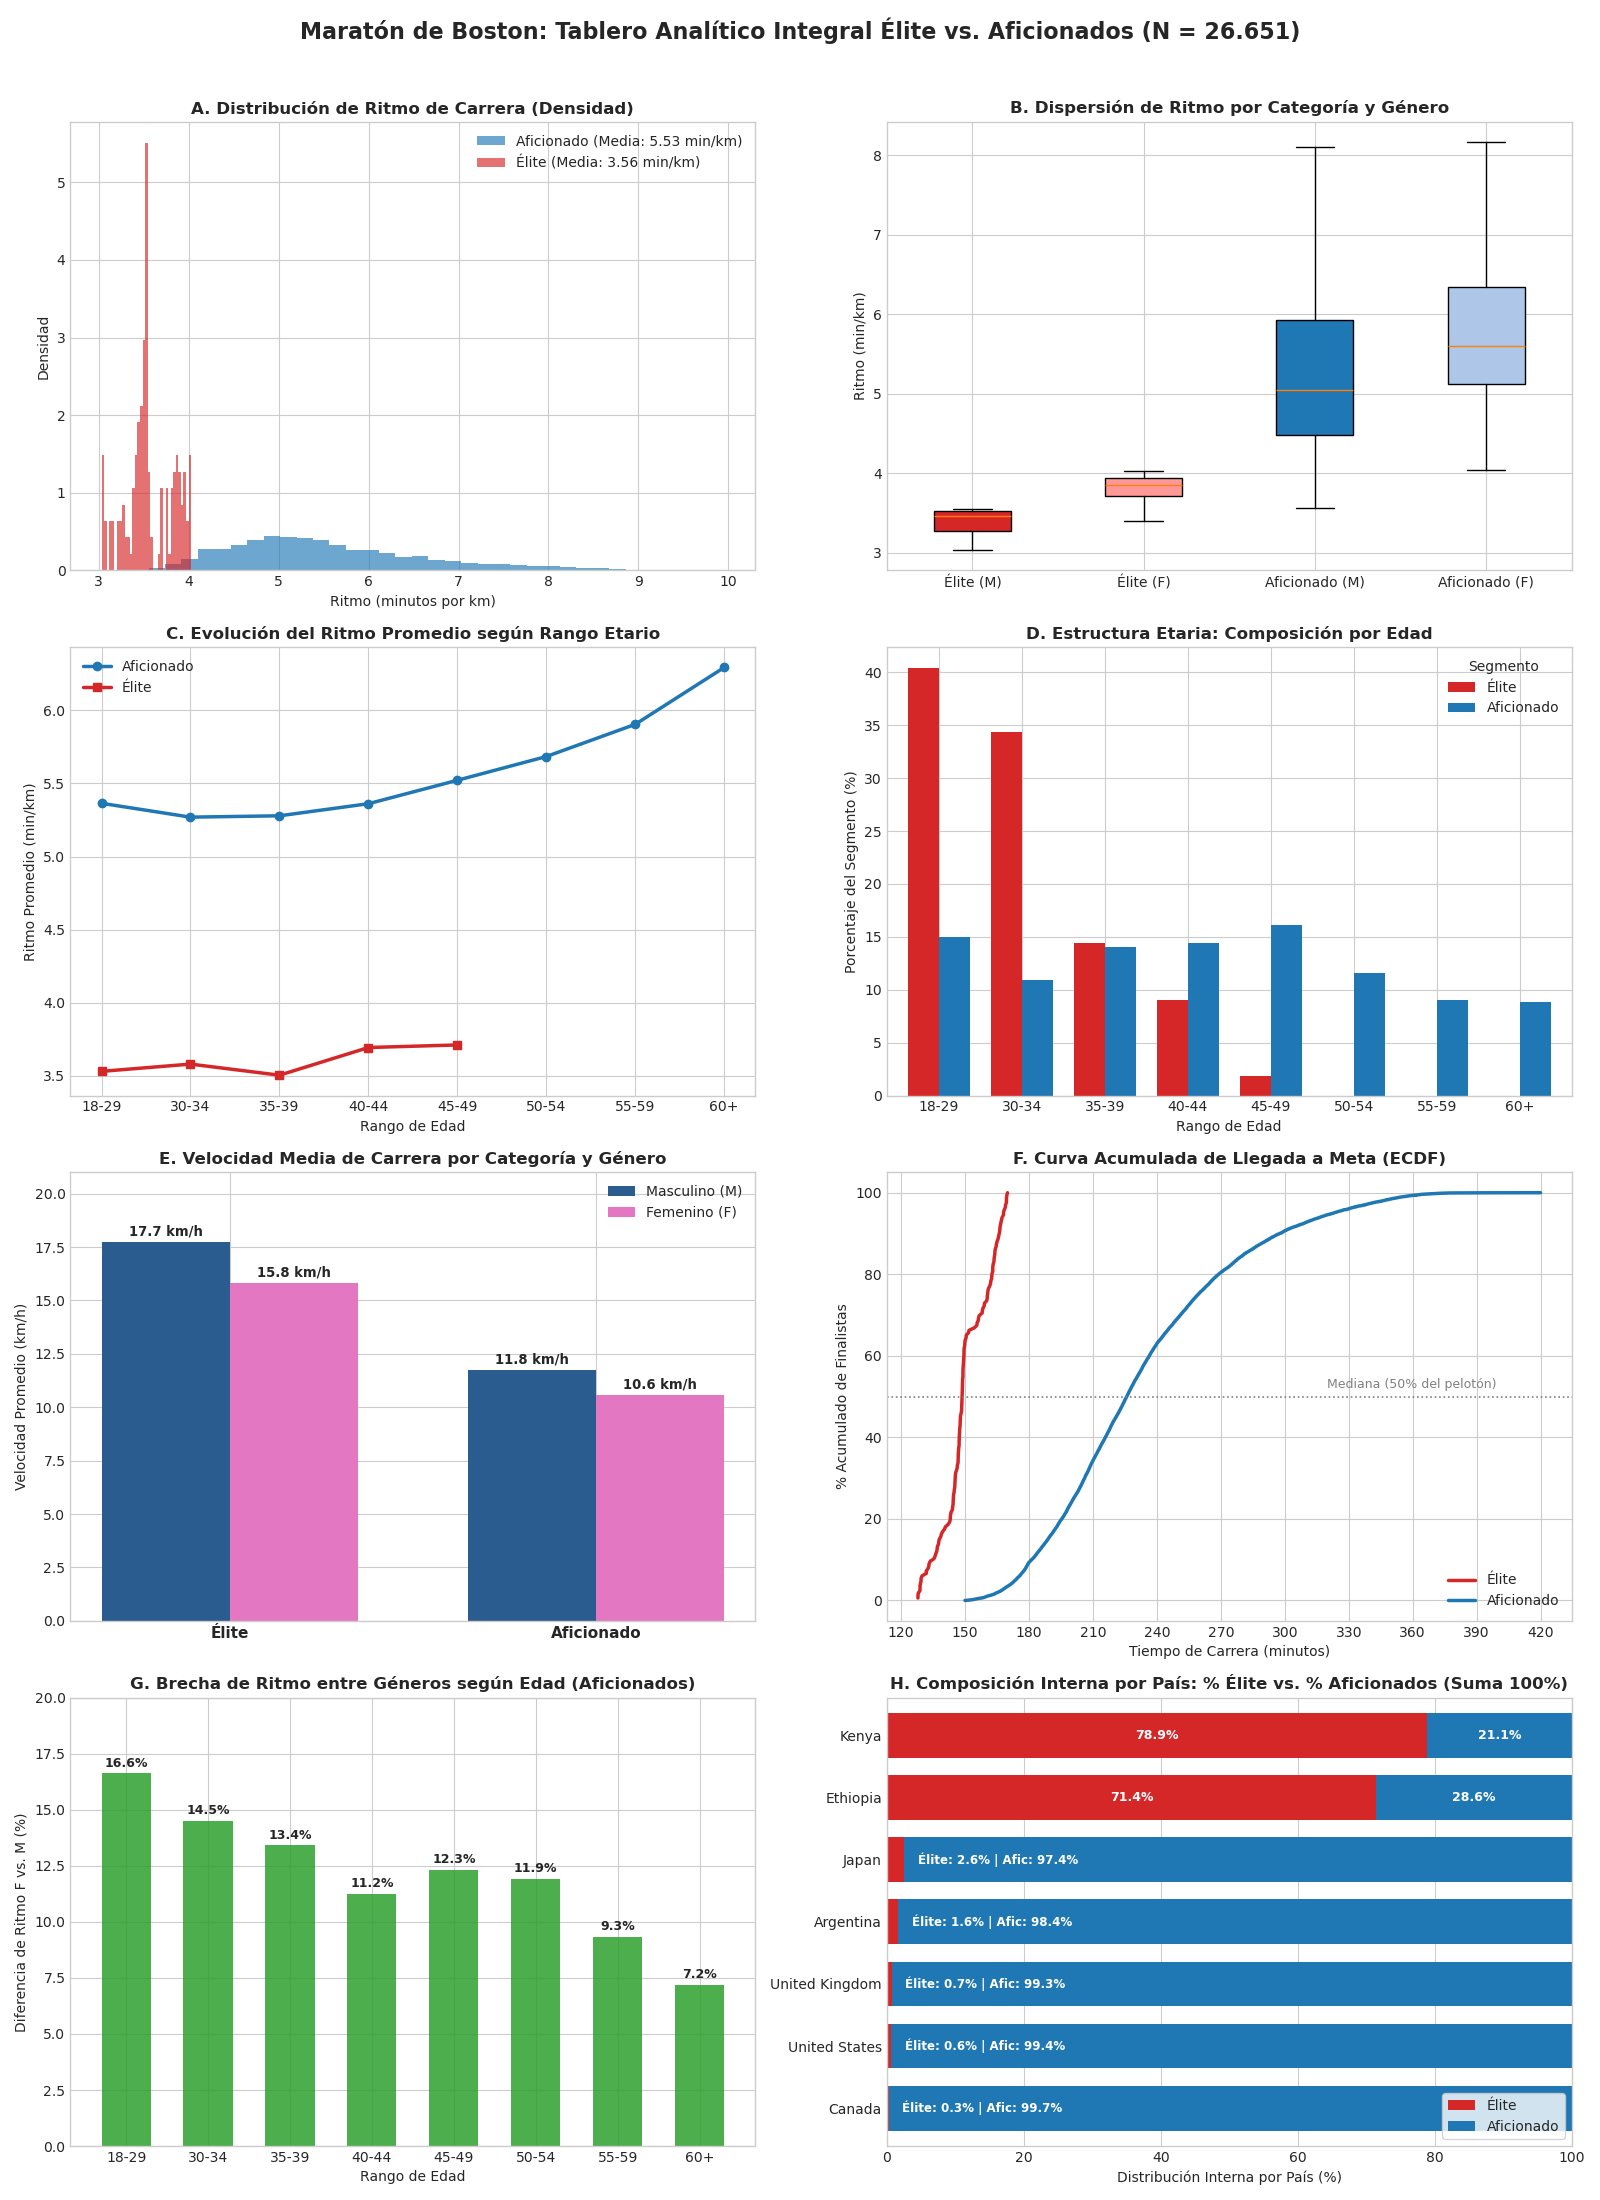

In [10]:
import base64
import io
import json
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Carga y limpieza
df = pd.read_csv("Dataset-Boston-2019.csv", sep=";")

# 2. Segmentación Élite vs. Aficionados
condicion_elite = ((df["Gender"] == "M") & (df["Result_sec"] < 9000)) | (
    (df["Gender"] == "F") & (df["Result_sec"] < 10200)
)
df["Segmento"] = np.where(condicion_elite, "Élite", "Aficionado")

# 3. Variables derivadas
DISTANCIA_KM = 42.195
df["Tiempo_min"] = df["Result_sec"] / 60.0
df["Tiempo_hr"] = df["Result_sec"] / 3600.0
df["Ritmo_min_km"] = df["Tiempo_min"] / DISTANCIA_KM
df["Velocidad_kmh"] = DISTANCIA_KM / df["Tiempo_hr"]

bins = [17, 29, 34, 39, 44, 49, 54, 59, 90]
labels = ["18-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59", "60+"]
df["Rango_Edad"] = pd.cut(df["Age"], bins=bins, labels=labels)

# 4. Panel de 8 Gráficos
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(16, 22))
fig.suptitle(
    "Maratón de Boston: Tablero Analítico Integral Élite vs. Aficionados (N ="
    " 26.651)",
    fontsize=16,
    fontweight="bold",
    y=0.992,
)
colores = {"Élite": "#d62728", "Aficionado": "#1f77b4"}

# A. Densidad de Ritmo
ax1 = axes[0, 0]
for seg in ["Aficionado", "Élite"]:
  sub = df[df["Segmento"] == seg]
  ax1.hist(
      sub["Ritmo_min_km"],
      bins=35,
      density=True,
      alpha=0.65,
      label=f"{seg} (Media: {sub['Ritmo_min_km'].mean():.2f} min/km)",
      color=colores[seg],
  )
ax1.set_title(
    "A. Distribución de Ritmo de Carrera (Densidad)", fontweight="bold"
)
ax1.set_xlabel("Ritmo (minutos por km)")
ax1.set_ylabel("Densidad")
ax1.legend()

# B. Boxplot por Categoría y Género
ax2 = axes[0, 1]
grupos_box = [
    df[(df["Segmento"] == "Élite") & (df["Gender"] == "M")]["Ritmo_min_km"],
    df[(df["Segmento"] == "Élite") & (df["Gender"] == "F")]["Ritmo_min_km"],
    df[(df["Segmento"] == "Aficionado") & (df["Gender"] == "M")][
        "Ritmo_min_km"
    ],
    df[(df["Segmento"] == "Aficionado") & (df["Gender"] == "F")][
        "Ritmo_min_km"
    ],
]
bp = ax2.boxplot(grupos_box, patch_artist=True, showfliers=False)
ax2.set_xticks([1, 2, 3, 4])
ax2.set_xticklabels(
    ["Élite (M)", "Élite (F)", "Aficionado (M)", "Aficionado (F)"]
)
for patch, color in zip(
    bp["boxes"], ["#d62728", "#ff9896", "#1f77b4", "#aec7e8"]
):
  patch.set_facecolor(color)
ax2.set_title("B. Dispersión de Ritmo por Categoría y Género", fontweight="bold")
ax2.set_ylabel("Ritmo (min/km)")

# C. Ritmo por Edad
ax3 = axes[1, 0]
ritmo_edad = (
    df.groupby(["Rango_Edad", "Segmento"], observed=False)["Ritmo_min_km"]
    .mean()
    .unstack()
)
ax3.plot(
    ritmo_edad.index,
    ritmo_edad["Aficionado"],
    marker="o",
    linewidth=2.5,
    color=colores["Aficionado"],
    label="Aficionado",
)
ax3.plot(
    ritmo_edad.index,
    ritmo_edad["Élite"],
    marker="s",
    linewidth=2.5,
    color=colores["Élite"],
    label="Élite",
)
ax3.set_title(
    "C. Evolución del Ritmo Promedio según Rango Etario", fontweight="bold"
)
ax3.set_xlabel("Rango de Edad")
ax3.set_ylabel("Ritmo Promedio (min/km)")
ax3.legend()

# D. Estructura Etaria
ax4 = axes[1, 1]
edad_pct = pd.crosstab(df["Rango_Edad"], df["Segmento"], normalize="columns") * 100
edad_pct[["Élite", "Aficionado"]].plot(
    kind="bar", ax=ax4, color=[colores["Élite"], colores["Aficionado"]], width=0.75
)
ax4.set_title("D. Estructura Etaria: Composición por Edad", fontweight="bold")
ax4.set_xlabel("Rango de Edad")
ax4.set_ylabel("Porcentaje del Segmento (%)")
ax4.tick_params(axis="x", rotation=0)

# E. Velocidad Promedio
ax5 = axes[2, 0]
vel_plot = (
    df.groupby(["Segmento", "Gender"])["Velocidad_kmh"]
    .mean()
    .unstack()
    .reindex(["Élite", "Aficionado"])
)
x = np.arange(len(vel_plot.index))
width = 0.35
rects1 = ax5.bar(
    x - width / 2, vel_plot["M"], width, label="Masculino (M)", color="#2b5c8f"
)
rects2 = ax5.bar(
    x + width / 2, vel_plot["F"], width, label="Femenino (F)", color="#e377c2"
)
for rect in rects1:
  h = rect.get_height()
  ax5.text(
      rect.get_x() + rect.get_width() / 2,
      h + 0.3,
      f"{h:.1f} km/h",
      ha="center",
      fontweight="bold",
      fontsize=9.5,
  )
for rect in rects2:
  h = rect.get_height()
  ax5.text(
      rect.get_x() + rect.get_width() / 2,
      h + 0.3,
      f"{h:.1f} km/h",
      ha="center",
      fontweight="bold",
      fontsize=9.5,
  )
ax5.set_title(
    "E. Velocidad Media de Carrera por Categoría y Género", fontweight="bold"
)
ax5.set_xticks(x)
ax5.set_xticklabels(["Élite", "Aficionado"], fontweight="bold", fontsize=11)
ax5.set_ylabel("Velocidad Promedio (km/h)")
ax5.set_ylim(0, 21)
ax5.legend()

# F. Curva Acumulada (ECDF)
ax6 = axes[2, 1]
for seg in ["Élite", "Aficionado"]:
  tiempos_ord = np.sort(df[df["Segmento"] == seg]["Tiempo_min"])
  pct_acum = np.arange(1, len(tiempos_ord) + 1) / len(tiempos_ord) * 100
  ax6.plot(tiempos_ord, pct_acum, linewidth=2.5, color=colores[seg], label=seg)
ax6.axhline(50, color="gray", linestyle=":", linewidth=1.2)
ax6.text(320, 52, "Mediana (50% del pelotón)", color="gray", fontsize=9)
ax6.set_title("F. Curva Acumulada de Llegada a Meta (ECDF)", fontweight="bold")
ax6.set_xlabel("Tiempo de Carrera (minutos)")
ax6.set_xticks(range(120, 450, 30))
ax6.set_ylabel("% Acumulado de Finalistas")
ax6.legend()

# G. Brecha de Género por Edad
ax7 = axes[3, 0]
afic = df[df["Segmento"] == "Aficionado"]
brecha = (
    afic.groupby(["Rango_Edad", "Gender"], observed=False)["Ritmo_min_km"]
    .mean()
    .unstack()
)
brecha["Brecha_pct"] = ((brecha["F"] - brecha["M"]) / brecha["M"]) * 100
bars = ax7.bar(
    brecha.index, brecha["Brecha_pct"], color="#2ca02c", alpha=0.85, width=0.6
)
for bar in bars:
  h = bar.get_height()
  ax7.text(
      bar.get_x() + bar.get_width() / 2,
      h + 0.3,
      f"{h:.1f}%",
      ha="center",
      fontsize=9,
      fontweight="bold",
  )
ax7.set_title(
    "G. Brecha de Ritmo entre Géneros según Edad (Aficionados)",
    fontweight="bold",
)
ax7.set_xlabel("Rango de Edad")
ax7.set_ylabel("Diferencia de Ritmo F vs. M (%)")
ax7.set_ylim(0, 20)

# H. Composición por País (100% Apilado + Argentina)
ax8 = axes[3, 1]
paises_sel = [
    "Canada",
    "United States",
    "United Kingdom",
    "Argentina",
    "Japan",
    "Ethiopia",
    "Kenya",
]
sub_p = df[df["Country"].isin(paises_sel)]
comp_pais = (
    pd.crosstab(sub_p["Country"], sub_p["Segmento"], normalize="index") * 100
)
comp_pais = comp_pais[["Élite", "Aficionado"]].reindex(paises_sel)
comp_pais.plot(
    kind="barh",
    stacked=True,
    ax=ax8,
    color=[colores["Élite"], colores["Aficionado"]],
    width=0.72,
)
for i, (pais, row) in enumerate(comp_pais.iterrows()):
  elite_val, afic_val = row["Élite"], row["Aficionado"]
  if elite_val >= 10:
    ax8.text(
        elite_val / 2,
        i,
        f"{elite_val:.1f}%",
        va="center",
        ha="center",
        color="white",
        fontweight="bold",
        fontsize=9,
    )
    ax8.text(
        elite_val + afic_val / 2,
        i,
        f"{afic_val:.1f}%",
        va="center",
        ha="center",
        color="white",
        fontweight="bold",
        fontsize=9,
    )
  else:
    ax8.text(
        elite_val + 2,
        i,
        f"Élite: {elite_val:.1f}% | Afic: {afic_val:.1f}%",
        va="center",
        ha="left",
        color="white",
        fontweight="bold",
        fontsize=8.5,
    )
ax8.set_title(
    "H. Composición Interna por País: % Élite vs. % Aficionados (Suma 100%)",
    fontweight="bold",
)
ax8.set_xlabel("Distribución Interna por País (%)")
ax8.set_ylabel("")
ax8.set_xlim(0, 100)
ax8.legend(loc="lower right", frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.98])

# Exportar imagen a memoria
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100)
plt.close(fig)
buf.seek(0)
img_b64 = base64.b64encode(buf.read()).decode("utf-8")

# 5. Datos para el Simulador Interactivo
elite_times = np.round(
    np.sort(df[df["Segmento"] == "Élite"]["Tiempo_min"].values), 2
).tolist()
afic_times = np.round(
    np.sort(df[df["Segmento"] == "Aficionado"]["Tiempo_min"].values), 2
).tolist()
payload = json.dumps({
    "elite": elite_times,
    "afic": afic_times,
    "mean_elite": round(float(np.mean(elite_times)), 2),
    "mean_afic": round(float(np.mean(afic_times)), 2),
    "dist": 42.195,
})

html_code = """
<div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; max-width: 1100px; margin: 0 auto; color: #222;">
  <div id="boston-sim" style="border: 1px solid #dcdcdc; border-radius: 12px; padding: 22px; background: #ffffff; box-shadow: 0 4px 12px rgba(0,0,0,0.06); margin-bottom: 24px;">
    <div style="display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 10px; margin-bottom: 14px;">
      <div>
        <h3 style="margin: 0; font-size: 19px; color: #111;">Simulador Interactivo: Progreso de Carrera (Maratón de Boston)</h3>
        <p style="margin: 4px 0 0 0; font-size: 13px; color: #555;">Mové la barra o presioná <b>Simular</b> para comparar el avance en tiempo real.</p>
      </div>
      <button id="sim-play-btn" style="background: #1f77b4; color: white; border: none; border-radius: 8px; padding: 9px 16px; font-weight: 600; cursor: pointer; font-size: 13px;">▶ Simular Carrera</button>
    </div>

    <div style="background: #f6f8fa; padding: 14px 16px; border-radius: 10px; margin-bottom: 18px; border: 1px solid #e5e8eb;">
      <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px;">
        <span style="font-weight: 600; font-size: 14px;">Tiempo transcurrido desde la largada:</span>
        <span id="sim-time-display" style="font-size: 18px; font-weight: 700; color: #d62728; font-variant-numeric: tabular-nums;">150 min (2:30:00)</span>
      </div>
      <input id="sim-slider" type="range" min="0" max="420" value="150" step="1" style="width: 100%; cursor: pointer; accent-color: #d62728;">
      <div style="display: flex; justify-content: space-between; font-size: 11px; color: #666; margin-top: 4px;">
        <span>0 min (Largada)</span>
        <span>128 min (1° Élite)</span>
        <span>170 min (100% Élite)</span>
        <span>226 min (50% Afic.)</span>
        <span>420 min (7:00h)</span>
      </div>
    </div>

    <div style="margin-bottom: 18px;">
      <div style="font-weight: 700; font-size: 14px; margin-bottom: 10px; color: #333;">1. Distancia promedio recorrida en ruta (Meta: 42,2 km)</div>
      <div style="margin-bottom: 12px;">
        <div style="display: flex; justify-content: space-between; font-size: 13px; margin-bottom: 4px;">
          <span style="font-weight: 600; color: #d62728;">Corredor Élite Promedio (Ritmo 3:34 /km)</span>
          <span id="elite-km-label" style="font-weight: 700;">42,1 km / 42,2 km</span>
        </div>
        <div style="width: 100%; background: #f0f0f0; height: 22px; border-radius: 11px; overflow: hidden;">
          <div id="elite-km-bar" style="height: 100%; width: 99%; background: linear-gradient(90deg, #ff6b6b, #d62728); transition: width 0.08s linear; border-radius: 11px;"></div>
        </div>
      </div>
      <div>
        <div style="display: flex; justify-content: space-between; font-size: 13px; margin-bottom: 4px;">
          <span style="font-weight: 600; color: #1f77b4;">Corredor Aficionado Promedio (Ritmo 5:32 /km)</span>
          <span id="afic-km-label" style="font-weight: 700;">27,1 km / 42,2 km</span>
        </div>
        <div style="width: 100%; background: #f0f0f0; height: 22px; border-radius: 11px; overflow: hidden;">
          <div id="afic-km-bar" style="height: 100%; width: 64%; background: linear-gradient(90deg, #5dade2, #1f77b4); transition: width 0.08s linear; border-radius: 11px;"></div>
        </div>
      </div>
    </div>

    <div style="font-weight: 700; font-size: 14px; margin-bottom: 10px; color: #333;">2. Pelotón que ya cruzó la línea de meta en este minuto</div>
    <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 12px;">
      <div style="background: #fff5f5; border: 1px solid #f5c6cb; border-radius: 10px; padding: 12px 15px;">
        <div style="font-size: 12px; color: #a71d2a; font-weight: 600;">FINALISTAS ÉLITE</div>
        <div id="elite-fin-pct" style="font-size: 24px; font-weight: 800; color: #d62728; margin: 2px 0;">62,7%</div>
        <div id="elite-fin-count" style="font-size: 12px; color: #555;">104 de 166 atletas</div>
      </div>
      <div style="background: #f0f7ff; border: 1px solid #b8daff; border-radius: 10px; padding: 12px 15px;">
        <div style="font-size: 12px; color: #004085; font-weight: 600;">FINALISTAS AFICIONADOS</div>
        <div id="afic-fin-pct" style="font-size: 24px; font-weight: 800; color: #1f77b4; margin: 2px 0;">0,0%</div>
        <div id="afic-fin-count" style="font-size: 12px; color: #555;">0 de 26.485 atletas</div>
      </div>
    </div>

    <div id="sim-insight" style="margin-top: 14px; padding: 10px 14px; background: #fffbea; border-left: 4px solid #f59f00; border-radius: 6px; font-size: 13px; color: #444;">
      En este minuto, más de la mitad de la élite ya cruzó la meta, mientras el pelotón aficionado recién transita el km 27.
    </div>
  </div>

  <div style="border: 1px solid #dcdcdc; border-radius: 12px; padding: 16px; background: #ffffff; box-shadow: 0 4px 12px rgba(0,0,0,0.06);">
    <img src="data:image/png;base64,__IMG_PLACEHOLDER__" alt="Panel de 8 Gráficos Comparativos" style="width: 100%; height: auto; display: block; border-radius: 8px;" />
  </div>
</div>

<script>
(function() {
  const data = __DATA_PLACEHOLDER__;
  const slider = document.getElementById("sim-slider");
  const timeDisplay = document.getElementById("sim-time-display");
  const eliteKmBar = document.getElementById("elite-km-bar");
  const aficKmBar = document.getElementById("afic-km-bar");
  const eliteKmLabel = document.getElementById("elite-km-label");
  const aficKmLabel = document.getElementById("afic-km-label");
  const eliteFinPct = document.getElementById("elite-fin-pct");
  const eliteFinCount = document.getElementById("elite-fin-count");
  const aficFinPct = document.getElementById("afic-fin-pct");
  const aficFinCount = document.getElementById("afic-fin-count");
  const insightBox = document.getElementById("sim-insight");
  const playBtn = document.getElementById("sim-play-btn");
  let playing = false, timer = null;

  function formatMin(m) {
    const h = Math.floor(m / 60);
    const min = Math.floor(m % 60);
    return `${h}:${String(min).padStart(2, '0')}:00`;
  }

  function countFinished(arr, t) {
    let lo = 0, hi = arr.length;
    while (lo < hi) {
      const mid = (lo + hi) >> 1;
      if (arr[mid] <= t) lo = mid + 1;
      else hi = mid;
    }
    return lo;
  }

  function update(t) {
    timeDisplay.textContent = `${t} min (${formatMin(t)})`;
    const kmElite = Math.min(data.dist, data.dist * (t / data.mean_elite));
    const kmAfic = Math.min(data.dist, data.dist * (t / data.mean_afic));
    eliteKmBar.style.width = `${(kmElite / data.dist) * 100}%`;
    aficKmBar.style.width = `${(kmAfic / data.dist) * 100}%`;
    eliteKmLabel.textContent = kmElite >= data.dist ? "42,2 km (¡Meta!)" : `${kmElite.toFixed(1).replace('.', ',')} km / 42,2 km`;
    aficKmLabel.textContent = kmAfic >= data.dist ? "42,2 km (¡Meta!)" : `${kmAfic.toFixed(1).replace('.', ',')} km / 42,2 km`;

    const finE = countFinished(data.elite, t);
    const finA = countFinished(data.afic, t);
    const pctE = (finE / data.elite.length) * 100;
    const pctA = (finA / data.afic.length) * 100;
    eliteFinPct.textContent = `${pctE.toFixed(1).replace('.', ',')}%`;
    eliteFinCount.textContent = `${finE.toLocaleString('es-AR')} de ${data.elite.length.toLocaleString('es-AR')} atletas`;
    aficFinPct.textContent = `${pctA.toFixed(1).replace('.', ',')}%`;
    aficFinCount.textContent = `${finA.toLocaleString('es-AR')} de ${data.afic.length.toLocaleString('es-AR')} atletas`;

    if (t === 0) {
      insightBox.textContent = "Largada en Hopkinton: los 26.651 corredores inician el recorrido de 42,195 km.";
    } else if (t < 128) {
      const diff = (kmElite - kmAfic).toFixed(1).replace('.', ',');
      insightBox.textContent = `Carrera en curso: el corredor élite promedio ya le sacó ${diff} km de ventaja al aficionado promedio.`;
    } else if (t >= 128 && t < 170) {
      insightBox.textContent = `¡Llegadas en la Élite! Ya cruzaron ${finE} atletas élite, mientras los aficionados promedio siguen cerca del km ${kmAfic.toFixed(1).replace('.', ',')}.`;
    } else if (t >= 170 && t < 226) {
      insightBox.textContent = `El 100% de la Élite ya terminó la carrera; en el pelotón aficionado recién llegó el ${pctA.toFixed(1).replace('.', ',')}%.`;
    } else if (t >= 226 && t < 300) {
      insightBox.textContent = `Hora pico en la meta: ya cruzó más de la mitad de los aficionados (${finA.toLocaleString('es-AR')} corredores).`;
    } else {
      insightBox.textContent = `Tramo final de la jornada: el ${pctA.toFixed(1).replace('.', ',')}% del pelotón aficionado completó el maratón.`;
    }
  }

  slider.addEventListener("input", () => update(Number(slider.value)));
  playBtn.addEventListener("click", () => {
    if (playing) {
      clearInterval(timer); playing = false; playBtn.textContent = "▶ Simular Carrera";
    } else {
      if (Number(slider.value) >= 420) slider.value = 0;
      playing = true; playBtn.textContent = "⏸ Pausar";
      timer = setInterval(() => {
        let next = Number(slider.value) + 2;
        if (next >= 420) {
          next = 420; clearInterval(timer); playing = false; playBtn.textContent = "▶ Simular Carrera";
        }
        slider.value = next; update(next);
      }, 60);
    }
  });
  update(150);
})();
</script>
"""

final_html = html_code.replace("__DATA_PLACEHOLDER__", payload).replace(
    "__IMG_PLACEHOLDER__", img_b64
)
display(HTML(final_html))